# 03 · Retrieval: five approaches compared

Statistic cards for different quarters, residency groups and seasonal bases differ by one word, so retrieval is the hard part of this task.
This notebook runs the approaches side by side on real questions and then summarises the full experiment from the saved results.

| ID | Approach | What it adds |
|---|---|---|
| R1 | BM25 (keyword) | exact words and numbers |
| R2 | Dense (`voyage-4` embeddings, cosine) | paraphrase and meaning |
| R3 | Hybrid: BM25 + dense merged by reciprocal rank fusion (RRF) | each retriever covers the other's misses |
| R4 | R3 top 20 re-ranked by a cross-encoder (Cohere `rerank-v3.5`) | reads query and passage together |
| R5 | R4 + a filter that drops chunks whose reference period is not one the question names | removes sibling cards for the wrong quarter |

All of them filter by the caller's role **before** ranking, so restricted chunks can never be retrieved. Metrics: Recall@5, hit@5, MRR@10, nDCG@10 against graded gold chunks.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

from policy_agent.eval.checks import load
from policy_agent.eval.models import RetrievalCase
from policy_agent.ingest.paths import ROOT
from policy_agent.retrieval.bm25 import get_bm25
from policy_agent.retrieval.corpus import tokenize, visible_chunks
from policy_agent.retrieval.dense import CACHE_DIR

load_dotenv()
sys.path.insert(0, str(ROOT / "scripts"))
import analyse_retrieval as ar  # noqa: E402

EMB = "voyageai/voyage-4"
cases = {c.id: c for c in load("retrieval_cases.jsonl", RetrievalCase)}
live = (CACHE_DIR / "voyageai__voyage-4.jsonl").exists() and "OPENROUTER_API_KEY" in os.environ
print(
    len(cases),
    "retrieval questions with gold chunks |",
    "dense and hybrid cells will run" if live else "no embedding cache or no key: dense and hybrid cells are skipped",
)

26 retrieval questions with gold chunks | dense and hybrid cells will run


## 1. The index and the permission filter
One index of text chunks and statistic cards, each with metadata. The role filter is applied first, so a public analyst's candidate set simply does not contain the internal memos.

In [2]:
public = {c["chunk_id"] for c in visible_chunks("analyst_public")}
internal = {c["chunk_id"] for c in visible_chunks("analyst_internal")}
print(
    f"chunks visible to analyst_public: {len(public):,} | to analyst_internal: {len(internal):,} | internal-only: {len(internal - public)}"
)
index = pd.DataFrame(visible_chunks("analyst_internal"))
display(index.groupby("doc_type").agg(chunks=("chunk_id", "count"), median_tokens=("tokens", "median")))

chunks visible to analyst_public: 2,436 | to analyst_internal: 2,438 | internal-only: 2


,chunks,median_tokens
doc_type,,
advance,140,148.0
annual_advance,42,235.5
explainer,5,122.0
memo,9,104.0
parliamentary_reply,5,200.0
quarterly_report,141,182.0
stat_card,2096,NaN


## 2. BM25 (R1)
Tokens are lowercase alphanumerics with thousands separators removed, so `4,620` and `4620` match. Good at exact numbers and rare words, blind to meaning, and unable to tell sibling cards apart when they share most of their words.

In [3]:
print(tokenize("Retrenchments rose to 4,620 in 2Q 2026 (resident, seasonally adjusted)"))


def gold_of(case_id, grade=2):
    return {k for k, g in cases[case_id].relevance.items() if g == grade}


def best_rank(hits, gold):
    ranks = [h.rank for h in hits if h.chunk["chunk_id"] in gold]
    return min(ranks) if ranks else None


def show(hits, gold, n=5):
    for h in hits[:n]:
        star = "*" if h.chunk["chunk_id"] in gold else " "
        print(f" {h.rank:2d} {star} {h.score:7.3f}  {h.chunk['doc_type']:<12} {h.chunk['text'][:100]!r}")


bm25 = get_bm25("analyst_public")
for cid in ("F03", "F02"):
    q = cases[cid].question
    hits = bm25.search(q, 200)
    print(
        f"\n{cid}: {q}\nBM25 top 5 (* = answer-bearing chunk); best answer-bearing rank: {best_rank(hits, gold_of(cid))}"
    )
    show(hits, gold_of(cid))

['retrenchments', 'rose', 'to', '4620', 'in', '2q', '2026', 'resident', 'seasonally', 'adjusted']

F03: What was the annual average citizen unemployment rate for 2024?
BM25 top 5 (* = answer-bearing chunk); best answer-bearing rank: 1
  1 *  16.081  stat_card    'Singapore citizen unemployment rate, annual average, the year 2024: 2.9% (Source: MOM via data.gov.s'
  2    14.464  stat_card    'Singapore citizen unemployment rate, annual average, the year 2025: 3% (Source: MOM via data.gov.sg,'
  3    14.464  stat_card    'Singapore citizen unemployment rate, annual average, the year 2023: 2.9% (Source: MOM via data.gov.s'
  4    14.464  stat_card    'Singapore citizen unemployment rate, annual average, the year 2022: 3.1% (Source: MOM via data.gov.s'
  5    14.194  quarterly_report 'In October 2021, the unemployment rate continued to improve for residents (3.4% (-0.1%-point)) and c'

F02: What was the overall unemployment rate, seasonally adjusted, in the fourth quarter of 2023?
BM25 top

## 3. Dense retrieval (R2)
Every chunk and the question are embedded and compared by cosine similarity. It finds paraphrases, but sibling cards (other quarters, other residency groups) look almost the same to it.

In [4]:
if live:
    from policy_agent.retrieval.dense import get_dense

    dense = get_dense("analyst_public", EMB)
    for cid in ("F03", "F02"):
        hits = dense.search(cases[cid].question, 200)
        print(f"\n{cid}: dense top 5; best answer-bearing rank: {best_rank(hits, gold_of(cid))}")
        show(hits, gold_of(cid))
else:
    print("skipped (needs the embedding cache and OPENROUTER_API_KEY; run a question once to build it)")


F03: dense top 5; best answer-bearing rank: 3
  1     0.702  advance      '9. Unemployment rates for residents and citizens rose slightly from September to October 2024 (resid'
  2     0.649  advance      '6. Unemployment rates declined in June 2024 compared to May 2024 (overall: from 2.1% to 2.0%; reside'
  3 *   0.647  stat_card    'Singapore citizen unemployment rate, annual average, the year 2024: 2.9% (Source: MOM via data.gov.s'
  4     0.637  advance      '5. Unemployment rates remained low in September 2024. The overall unemployment rate dipped to 1.8% i'
  5     0.616  quarterly_report '9. Unemployment rates inched up in March 2024 (overall: 2.1%; resident: 3.0%; citizen: 3.1%) compare'

F02: dense top 5; best answer-bearing rank: 10
  1     0.583  quarterly_report '8. Unemployment rates remained stable and low in December 2023 (overall: 2.0%; resident: 2.8%; citiz'
  2     0.570  quarterly_report '8. The unemployment rates remained low and stable in December 2024 (overall: 1

## 4. Fusion, re-ranking and the period filter (R3 to R5)
RRF scores each chunk as the sum of `1/(60 + rank)` over the lists it appears in, so a chunk both retrievers like beats one that only a single retriever ranks first. The re-ranker then reads the question and each of the top 20 together. R5 also drops chunks about periods the question never mentions.

In [5]:
if live:
    from policy_agent.retrieval.hybrid import get_hybrid

    systems = {
        "R1 BM25": lambda q: bm25.search(q, 200),
        "R2 dense": lambda q: dense.search(q, 200),
        "R3 fusion": lambda q: get_hybrid("analyst_public", "r3", EMB).search(q, 100),
        "R4 +re-rank": lambda q: get_hybrid("analyst_public", "r4", EMB).search(q, 20),
        "R5 +period filter": lambda q: get_hybrid("analyst_public", "r5", EMB).search(q, 20),
    }
    dev = [c for c in cases.values() if c.split == "dev"]
    rows = []
    for c in dev:
        gold = {k for k, g in c.relevance.items() if g == 2}
        rows.append({"question": c.id} | {name: best_rank(fn(c.question), gold) for name, fn in systems.items()})
    ranks = pd.DataFrame(rows).set_index("question")
    print(
        "rank of the best answer-bearing chunk, dev questions (None = not in the returned list; R4 and R5 return 20, R3 returns 100)"
    )
    display(ranks)
    top5 = (ranks.fillna(10**6) <= 5).mean().rename("share of questions with an answer-bearing chunk in the top 5")
    display(top5.to_frame())
else:
    print("skipped (needs the embedding cache and OPENROUTER_API_KEY)")

rank of the best answer-bearing chunk, dev questions (None = not in the returned list; R4 and R5 return 20, R3 returns 100)


,R1 BM25,R2 dense,R3 fusion,R4 +re-rank,R5 +period filter
question,,,,,
C03,2.0,9,7,3.0,5
C04,5.0,1,1,2.0,2
D02,36.0,3,7,2.0,2
F02,110.0,10,23,NaN,1
F03,1.0,3,1,2.0,2
F05,2.0,1,1,1.0,1
F06,10.0,1,1,1.0,1
F07,38.0,11,4,2.0,2
K02,29.0,1,2,1.0,1


,share of questions with an answer-bearing chunk in the top 5
R1 BM25,0.533333
R2 dense,0.666667
R3 fusion,0.600000
R4 +re-rank,0.800000
R5 +period filter,0.866667


## 5. The full experiment, from the saved results
The same four systems on all questions with gold evidence, on the development split (used for design) and the held-out test split. Intervals are 95% bootstrap over questions; the paired difference against BM25 uses the same resamples.

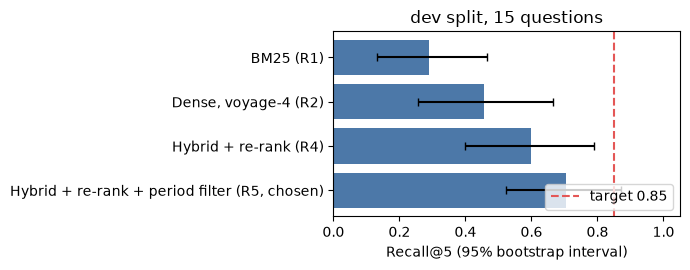

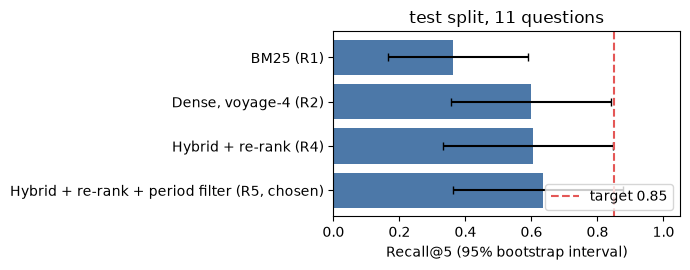

In [7]:
for split in ("dev", "test"):
    res = ar.load(split)
    cases_s = sorted(k for k in res["E1"] if k != "_meta")
    idx = np.random.default_rng(ar.SEED).integers(0, len(cases_s), size=(ar.N_BOOT, len(cases_s)))
    rows = []
    for cid, label in ar.SYSTEMS:
        v = np.array([res[cid][c]["recall_at_5"] for c in cases_s])
        mean, lo, hi = ar.ci(v, idx)
        rows.append((label, mean, lo, hi))
    plt.figure(figsize=(7, 2.8))
    ys = range(len(rows))
    plt.barh(
        list(ys),
        [r[1] for r in rows],
        xerr=[[r[1] - r[2] for r in rows], [r[3] - r[1] for r in rows]],
        color="#4C78A8",
        capsize=3,
    )
    plt.yticks(list(ys), [r[0] for r in rows])
    plt.gca().invert_yaxis()
    plt.axvline(0.85, color="#E45756", linestyle="--", label="target 0.85")
    plt.xlim(0, 1.05)
    plt.xlabel("Recall@5 (95% bootstrap interval)")
    plt.title(f"{split} split, {len(cases_s)} questions")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

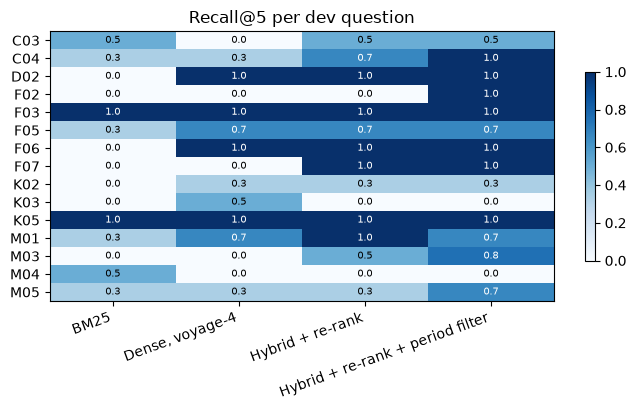

questions that no system retrieves (Recall@5 = 0 everywhere): []


In [8]:
res = ar.load("dev")
per_q = pd.DataFrame(
    {label: {c: res[cid][c]["recall_at_5"] for c in res[cid] if c != "_meta"} for cid, label in ar.SYSTEMS}
)
fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(per_q.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(per_q.shape[1]))
ax.set_xticklabels([c.split(" (")[0] for c in per_q.columns], rotation=20, ha="right")
ax.set_yticks(range(per_q.shape[0]))
ax.set_yticklabels(per_q.index)
for i in range(per_q.shape[0]):
    for j in range(per_q.shape[1]):
        ax.text(
            j,
            i,
            f"{per_q.values[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=7,
            color="black" if per_q.values[i, j] < 0.6 else "white",
        )
ax.set_title("Recall@5 per dev question")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()
still_missing = per_q.index[(per_q == 0).all(axis=1)].tolist()
print("questions that no system retrieves (Recall@5 = 0 everywhere):", still_missing)

## What this shows

- **BM25 and dense retrieval fail on different questions.** In the rank table, BM25 is better on some (C03, F03, M04: it repeats the card's exact words) and dense retrieval on others (C04, D02, F02, F07, K02, M03: paraphrase and meaning). Fusion alone does not reliably combine them: for F02, BM25 ranks the answer 110th and dense 10th, and the fused list puts it 23rd, because a middling rank in both can beat a first rank in one.
- **The re-ranker is what turns candidates into answers.** It reads the question and each candidate together, so it can tell the right quarter and residency group apart, which neither first-stage retriever can. It only sees the top 20 candidates, so F02 (fused rank 23) is missed by R4 (shown as None) and recovered by R5, whose period filter removes the other quarters before the re-ranker runs.
- **Nothing reaches the 0.85 target.** On the held-out split the best system has Recall@5 0.64; questions such as K03 and M04 still rank their answer beyond the top 5 even with R5 (the agent recovers some of these by calling the statistics tool instead of relying on retrieval).
- The numbers, confidence intervals and the conclusion on hypothesis H1 are in `docs/EVAL_REPORT.md` section 4.